In [2]:
from Instruments import *
from pyspecdata import *
import time
from serial.tools.list_ports import comports
import serial
import numpy as np

# note that this requires the serial library!

# {{{ this section is just diagnostic, to check that it can see the
# instruments -- it's possible that with upgraded libraries, this will not work
print("These are the instruments available:")
SerialInstrument(None)
print("done printing available instruments")
with SerialInstrument("AFG-2225") as s:
    print(s.respond("*idn?"))
# }}}

def gen_pulse(freq=14.5e6, width=4e-6, ch1_only=True):
    with AFG() as a:
        a.reset()
        # {{{ here, we manually construct an ndarry that gives the
        #     square pulse waveform
        rate = freq * 4
        total_samples = width * rate
        total_samples = (
            int(total_samples / 4 + 0.5) * 4
        )  # convert to multiple of 4
        assert total_samples < 4097, (
            "Your pattern length (%d) exceeds the max (4096 samples at %g MHz)"
            % (total_samples, rate)
        )
        y = np.zeros(total_samples)
        y[0::4] = 0
        y[1::4] = 1
        y[2::4] = 0
        y[3::4] = -1
        y[-1] = 0
        # }}}
        this_ch = 0  # do everything on channel 1
        a[this_ch].digital_ndarray(y, rate=rate)
        print("now, output on")
        a[this_ch].output = True
        a[this_ch].burst = True
        a.set_burst(
            per=500e-6
        )  # this is how often the waveform (a square pulse) is played out
        a[this_ch].ampl = 1.0


gen_pulse()

These are the instruments available:
done printing available instruments
port dict has no results, so searching for instruments
this is the port dictionary that I generate: {}
I looped through all the com ports and didn't find  AFG-2225 resetting port_dict, and trying again
port dict has no results, so searching for instruments
this is the port dictionary that I generate: {}
I looped through all the com ports and didn't find  AFG-2225 resetting port_dict, and trying again
port dict has no results, so searching for instruments
this is the port dictionary that I generate: {}
I looped through all the com ports and didn't find  AFG-2225 resetting port_dict, and trying again
port dict has no results, so searching for instruments
this is the port dictionary that I generate: {}
I looped through all the com ports and didn't find  AFG-2225 resetting port_dict, and trying again
port dict has no results, so searching for instruments
this is the port dictionary that I generate: {}
I looped through

RuntimeError: maxed out attempts to id instrument

In [15]:
Vpp = 750e-3
Vrms = Vpp/2/sqrt(2)
Vrms**2 / 50 * 10**(40/10)

14.062499999999996

In [21]:
Vpp = 1.25
Vrms = Vpp/2/sqrt(2)
Vrms**2 / 50

39.06249999999999

In [23]:
V_rms = 1.2
V_rms**2 /50

0.0288

In [8]:
sqrt(2000)

44.721359549995796

In [24]:
sqrt(40*50*10**-4)*2*sqrt(2)

1.2649110640673518

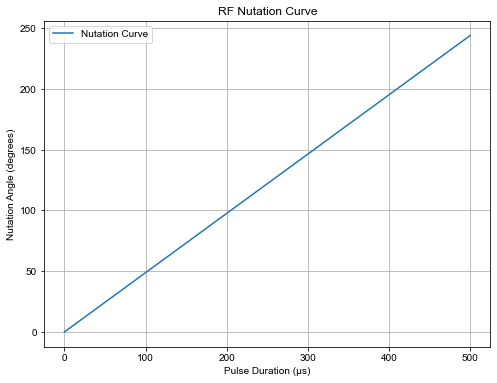

In [30]:
#nutation curve chatgpt
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
gamma = 42.58e6  # gyromagnetic ratio for proton in Hz/T
B1 = 1e-4  # RF field strength in Tesla
t_pulse = np.linspace(0, 500e-6, 1000)  # Pulse duration in seconds

# Calculate nutation angle in degrees
nutation_angle = (gamma * B1 * t_pulse) * (180 / np.pi)  # converting to degrees

# Plot the nutation curve
plt.figure(figsize=(8, 6))
plt.plot(t_pulse * 1e6, nutation_angle, label='Nutation Curve')
plt.xlabel('Pulse Duration (µs)')
plt.ylabel('Nutation Angle (degrees)')
plt.title('RF Nutation Curve')
plt.grid(True)
plt.legend()
plt.show()


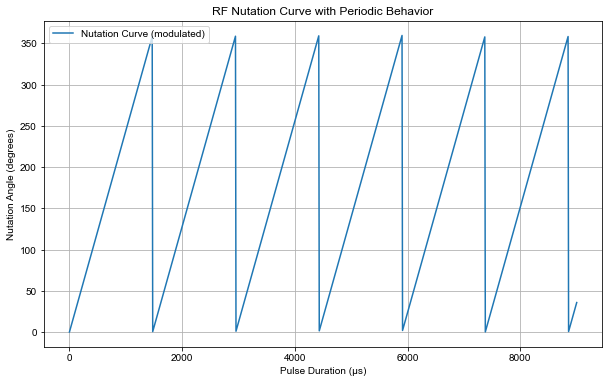

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
gamma = 42.58e6  # gyromagnetic ratio for proton in Hz/T
B1 = 1e-4  # RF field strength in Tesla
t_pulse = np.linspace(0, 9000e-6, 1000)  # Extended pulse duration in seconds

# Calculate nutation angle in degrees
nutation_angle = (gamma * B1 * t_pulse) * (180 / np.pi)  # converting to degrees

# Modulate angle to keep within 0 to 360 degrees to show periodicity
nutation_angle_modulated = nutation_angle % 360

# Plot the nutation curve
plt.figure(figsize=(10, 6))
plt.plot(t_pulse * 1e6, nutation_angle_modulated, label='Nutation Curve (modulated)')
plt.xlabel('Pulse Duration (µs)')
plt.ylabel('Nutation Angle (degrees)')
plt.title('RF Nutation Curve with Periodic Behavior')
plt.grid(True)
plt.legend()
plt.show()
